In [10]:
!pip install defisheye

In [11]:
%pip install datasets defisheye matplotlib pillow

In [15]:
from google.colab import userdata
from huggingface_hub import login

hf_token = userdata.get("HF_TOKEN")
login(token=hf_token)  # paste the token from discord

In [16]:
from datasets import load_dataset

# Stream images from the CanopyMap dataset
train_ds = load_dataset(
    "regularpooria/canopymap_plants",
    split="train",
    streaming=True
)

print(train_ds)

README.md:   0%|          | 0.00/458 [00:00<?, ?B/s]

IterableDataset({
    features: ['image', 'channel', 'date', 'time', 'suitable'],
    num_shards: 3
})


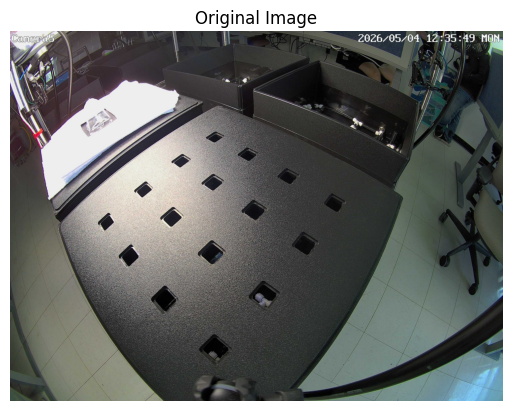

In [28]:
import matplotlib.pyplot as plt

# Select the first image
sample = next(iter(train_ds))
img = sample["image"]

# Display the image
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [27]:
# Save the selected image to Colab
img.save("image.jpg")

print("Image saved successfully")

Image saved successfully


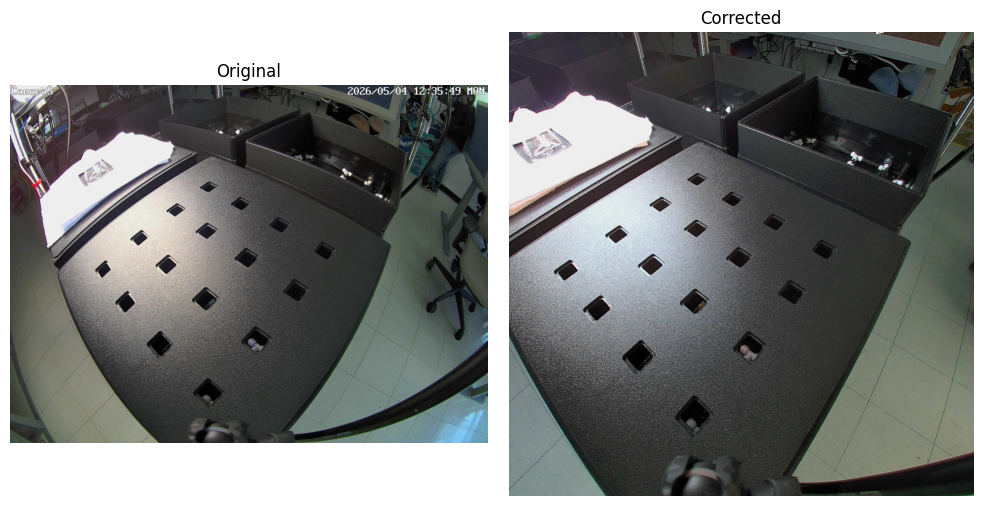

In [32]:
import matplotlib.pyplot as plt
from PIL import Image
from defisheye import Defisheye

# Correction parameters
img_kwargs = {
    "fov": 116,
    "pfov": 100,
    "dtype": "equalarea",
    "format": "fullframe"
}

# Correct the image
obj = Defisheye("image.jpg", **img_kwargs)
undistorted_img = obj.convert()

# Display original and corrected images
original_img = Image.open("image.jpg")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("Original")
plt.imshow(original_img)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title("Corrected")
plt.imshow(undistorted_img)
plt.axis("off")

plt.tight_layout()
plt.show()